<a href="https://colab.research.google.com/github/25041098-mxitd/Covid19-Estadistica-Itd-Unidad-VI/blob/main/Analisis_COVID19_Mexico_2020_2021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis Estadístico y Probabilístico de Casos COVID-19 en México (2020–2021)

- **Institución:** Instituto Tecnológico de Durango (TecNM)
- **Carrera:** Ingeniería en Sistemas Computacionales
- **Asignatura:** Probabilidad y Estadística
- **Grupo:** 2Y
- **Periodo del Semestre:** Agosto – Diciembre 2026
- **Fecha de Entrega:** 27 de noviembre del 2026
- **Docente:** Jose Gabriel Rodriguez Rivas
- **Integrantes del Equipo:**
  - Aaron Antonio Contreras Herrera (No. Control: 25041016)
  - Yael Arturo Aparicio Guzman (No. Control: 25041005)
  - Yahir Fernando Vargas Calderón (No. Control: 25041098)
- **Dataset:** `covid2020-2021-codificado.csv` (12,634,194 registros epidemiológicos de México)

---

### Objetivo del Proyecto
Aplicar los conceptos de probabilidad y estadística mediante Python para desarrollar un análisis descriptivo, visual y probabilístico sobre los registros oficiales de COVID-19 en México (2020–2021), evaluando variables demográficas, evolución temporal, probabilidad simple y condicional de comorbilidades por entidad federativa y modelado mediante distribución normal.


## 1. Carga de Datos y Configuración

El archivo `covid2020-2021-codificado.csv` contiene más de 12.63 millones de registros (~1.5 GB). Para cargarlo completo en Google Colab sin exceder la memoria disponible, se seleccionan únicamente las 16 columnas necesarias para el análisis y se asigna el tipo `category` a las variables repetitivas.

In [3]:
# Importar librerías para manejo de datos, visualización y análisis estadístico
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.stats import norm
import gc
import warnings

# Configuración general del entorno y estilo visual de las gráficas
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# Conectar Google Drive para acceder al dataset
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
# Ruta del archivo CSV en Google Drive
RUTA_CSV = '/content/drive/MyDrive/covid2020-2021-codificado.csv'

# Seleccionar únicamente las columnas necesarias para el análisis
columnas_estudio = [
    'SEXO', 'ENTIDAD_NAC', 'TIPO_PACIENTE', 'FECHA_INGRESO',
    'EDAD', 'EMBARAZO', 'INDIGENA',
    'DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION',
    'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO',
    'RESULTADO_ANTIGENO'
]

# Asignar tipos optimizados para reducir el consumo de memoria RAM
dtypes_col = {
    'SEXO': 'category',
    'ENTIDAD_NAC': 'category',
    'TIPO_PACIENTE': 'category',
    'EDAD': 'float32',
    'EMBARAZO': 'category',
    'INDIGENA': 'category',
    'DIABETES': 'category',
    'EPOC': 'category',
    'ASMA': 'category',
    'HIPERTENSION': 'category',
    'CARDIOVASCULAR': 'category',
    'OBESIDAD': 'category',
    'RENAL_CRONICA': 'category',
    'TABAQUISMO': 'category',
    'RESULTADO_ANTIGENO': 'category'
}

# Cargar el dataset utilizando únicamente las columnas seleccionadas
print("Cargando dataset...")
df = pd.read_csv(
    RUTA_CSV,
    usecols=columnas_estudio,
    dtype=dtypes_col,
    encoding='utf-8'
)

# Convertir la fecha de ingreso al formato datetime
df['FECHA_INGRESO'] = pd.to_datetime(
    df['FECHA_INGRESO'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

# Liberar memoria temporal no utilizada
gc.collect()

# Mostrar información general del dataset cargado
memoria_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Registros cargados: {len(df):,}")
print(f"Columnas: {df.shape[1]}")
print(f"Memoria utilizada: {memoria_mb:.2f} MB")

Cargando dataset...
Registros cargados: 12,634,194
Columnas: 16
Memoria utilizada: 313.28 MB


## 2. Estadística Descriptiva General

En esta sección obtenemos las frecuencias absolutas y relativas (porcentajes) sobre los **12.63 millones de registros** para las variables demográficas y clínicas clave:
* **Resultado de prueba de antígeno (`RESULTADO_ANTIGENO`):** Positivo, Negativo y Pendiente.
* **Tipo de atención médica (`TIPO_PACIENTE`):** Ambulatorio vs. Hospitalizado.
* **Distribución por sexo (`SEXO`):** Femenino y Masculino.
* **Condición de embarazo (`EMBARAZO`):** Conteo total y proporción calculada específicamente sobre la población femenina.
* **Población indígena (`INDIGENA`):** Autoidentificación indígena.
* **Medidas de tendencia central y dispersión de la edad (`EDAD`):** Media, mediana, desviación estándar, rango intercuartílico (IQR), mínimo y máximo.


In [15]:
total_registros = len(df)

def tabla_frecuencias(serie, nombre_var):
    conteos = serie.value_counts(dropna=False)
    porcentajes = (conteos / total_registros) * 100
    resumen = pd.DataFrame({
        'Variable': nombre_var,
        'Categoría': conteos.index.astype(str),
        'Frecuencia Absoluta': conteos.values,
        'Porcentaje (%)': np.round(porcentajes.values, 2)
    })
    return resumen

t_resultado = tabla_frecuencias(df['RESULTADO_ANTIGENO'], 'Resultado Antígeno')
t_paciente = tabla_frecuencias(df['TIPO_PACIENTE'], 'Tipo de Paciente')
t_sexo = tabla_frecuencias(df['SEXO'], 'Sexo')
t_embarazo = tabla_frecuencias(df['EMBARAZO'], 'Embarazo (Total)')
t_indigena = tabla_frecuencias(df['INDIGENA'], 'Indígena')

tabla_general = pd.concat([t_resultado, t_paciente, t_sexo, t_embarazo, t_indigena], ignore_index=True)

print("=== RESUMEN DESCRIPTIVO GENERAL ===")
display(tabla_general.style.format({'Frecuencia Absoluta': '{:,}', 'Porcentaje (%)': '{:.2f}%'}))

# Desglose de embarazo únicamente en mujeres
mujeres_df = df[df['SEXO'] == 'Femenino']
emb_mujeres = mujeres_df['EMBARAZO'].value_counts()
print(f"\n=== EMBARAZO EN POBLACIÓN FEMENINA (Total: {len(mujeres_df):,}) ===")
for cat, val in emb_mujeres.items():
    print(f"  - {cat}: {val:,} ({val / len(mujeres_df) * 100:.2f}%)")

del mujeres_df
gc.collect()

# Estadísticos de edad (rango 0 a 120 años)
edad_valida = df['EDAD'][(df['EDAD'] >= 0) & (df['EDAD'] <= 120)]
stats_edad = pd.DataFrame({
    'Métrica': ['Registros válidos', 'Media', 'Desviación Estándar', 'Mínimo', 'Percentil 25 (Q1)', 'Mediana (Q2)', 'Percentil 75 (Q3)', 'Rango Intercuartílico (IQR)', 'Máximo'],
    'Valor': [
        f"{len(edad_valida):,}",
        f"{edad_valida.mean():.2f} años",
        f"{edad_valida.std():.2f} años",
        f"{edad_valida.min():.0f} años",
        f"{edad_valida.quantile(0.25):.0f} años",
        f"{edad_valida.median():.0f} años",
        f"{edad_valida.quantile(0.75):.0f} años",
        f"{(edad_valida.quantile(0.75) - edad_valida.quantile(0.25)):.0f} años",
        f"{edad_valida.max():.0f} años"
    ]
})
print("\n=== ESTADÍSTICOS DESCRIPTIVOS DE EDAD ===")
display(stats_edad)


=== RESUMEN DESCRIPTIVO GENERAL ===


,Variable,Categoría,Frecuencia Absoluta,Porcentaje (%)
0,Resultado Antígeno,Negativo,"5,853,547",46.33%
1,Resultado Antígeno,Pendiente,"5,005,939",39.62%
2,Resultado Antígeno,Positivo,"1,774,708",14.05%
3,Tipo de Paciente,Ambulatorio,"11,543,303",91.37%
4,Tipo de Paciente,Hospitalizado,"1,090,891",8.63%
5,Sexo,Femenino,"6,648,738",52.62%
6,Sexo,Masculino,"5,985,456",47.38%
7,Embarazo (Total),No,"6,483,614",51.32%
8,Embarazo (Total),No aplica,"5,985,456",47.38%
9,Embarazo (Total),Si,"122,583",0.97%



=== EMBARAZO EN POBLACIÓN FEMENINA (Total: 6,648,738) ===
  - No: 6,483,614 (97.52%)
  - Si: 122,583 (1.84%)
  - Se ignora: 42,529 (0.64%)
  - No especificado: 12 (0.00%)
  - No aplica: 0 (0.00%)

=== ESTADÍSTICOS DESCRIPTIVOS DE EDAD ===


,Métrica,Valor
0,Registros válidos,"12,630,604"
1,Media,38.70 años
2,Desviación Estándar,16.97 años
3,Mínimo,0 años
4,Percentil 25 (Q1),26 años
5,Mediana (Q2),37 años
6,Percentil 75 (Q3),50 años
7,Rango Intercuartílico (IQR),24 años
8,Máximo,120 años


Nota: La variable INDIGENA contiene una cantidad considerable de valores faltantes (NaN), por lo que los porcentajes reportados reflejan la distribución observada en la base de datos original sin realizar imputaciones ni modificaciones.

## 3. Visualizaciones Estadísticas del Dataset

Se construyen **6 visualizaciones** para explorar la distribución geográfica, demográfica, temporal y clínica de los registros:
1. **Gráfica 1:** Barras horizontales de registros totales y casos positivos por entidad de nacimiento (`ENTIDAD_NAC`).
2. **Gráfica 2:** Histograma de distribución de `EDAD` comparando población general y casos positivos.
3. **Gráfica 3:** Serie de tiempo mensual por fecha de ingreso (`FECHA_INGRESO`).
4. **Gráfica 4:** Barras apiladas por `SEXO` y `RESULTADO_ANTIGENO`.
5. **Gráfica 5:** Gráfico circular (dona) de `TIPO_PACIENTE` (`Ambulatorio` vs. `Hospitalizado`).
6. **Gráfica 6:** Barras horizontales comparativas de prevalencia por comorbilidad.


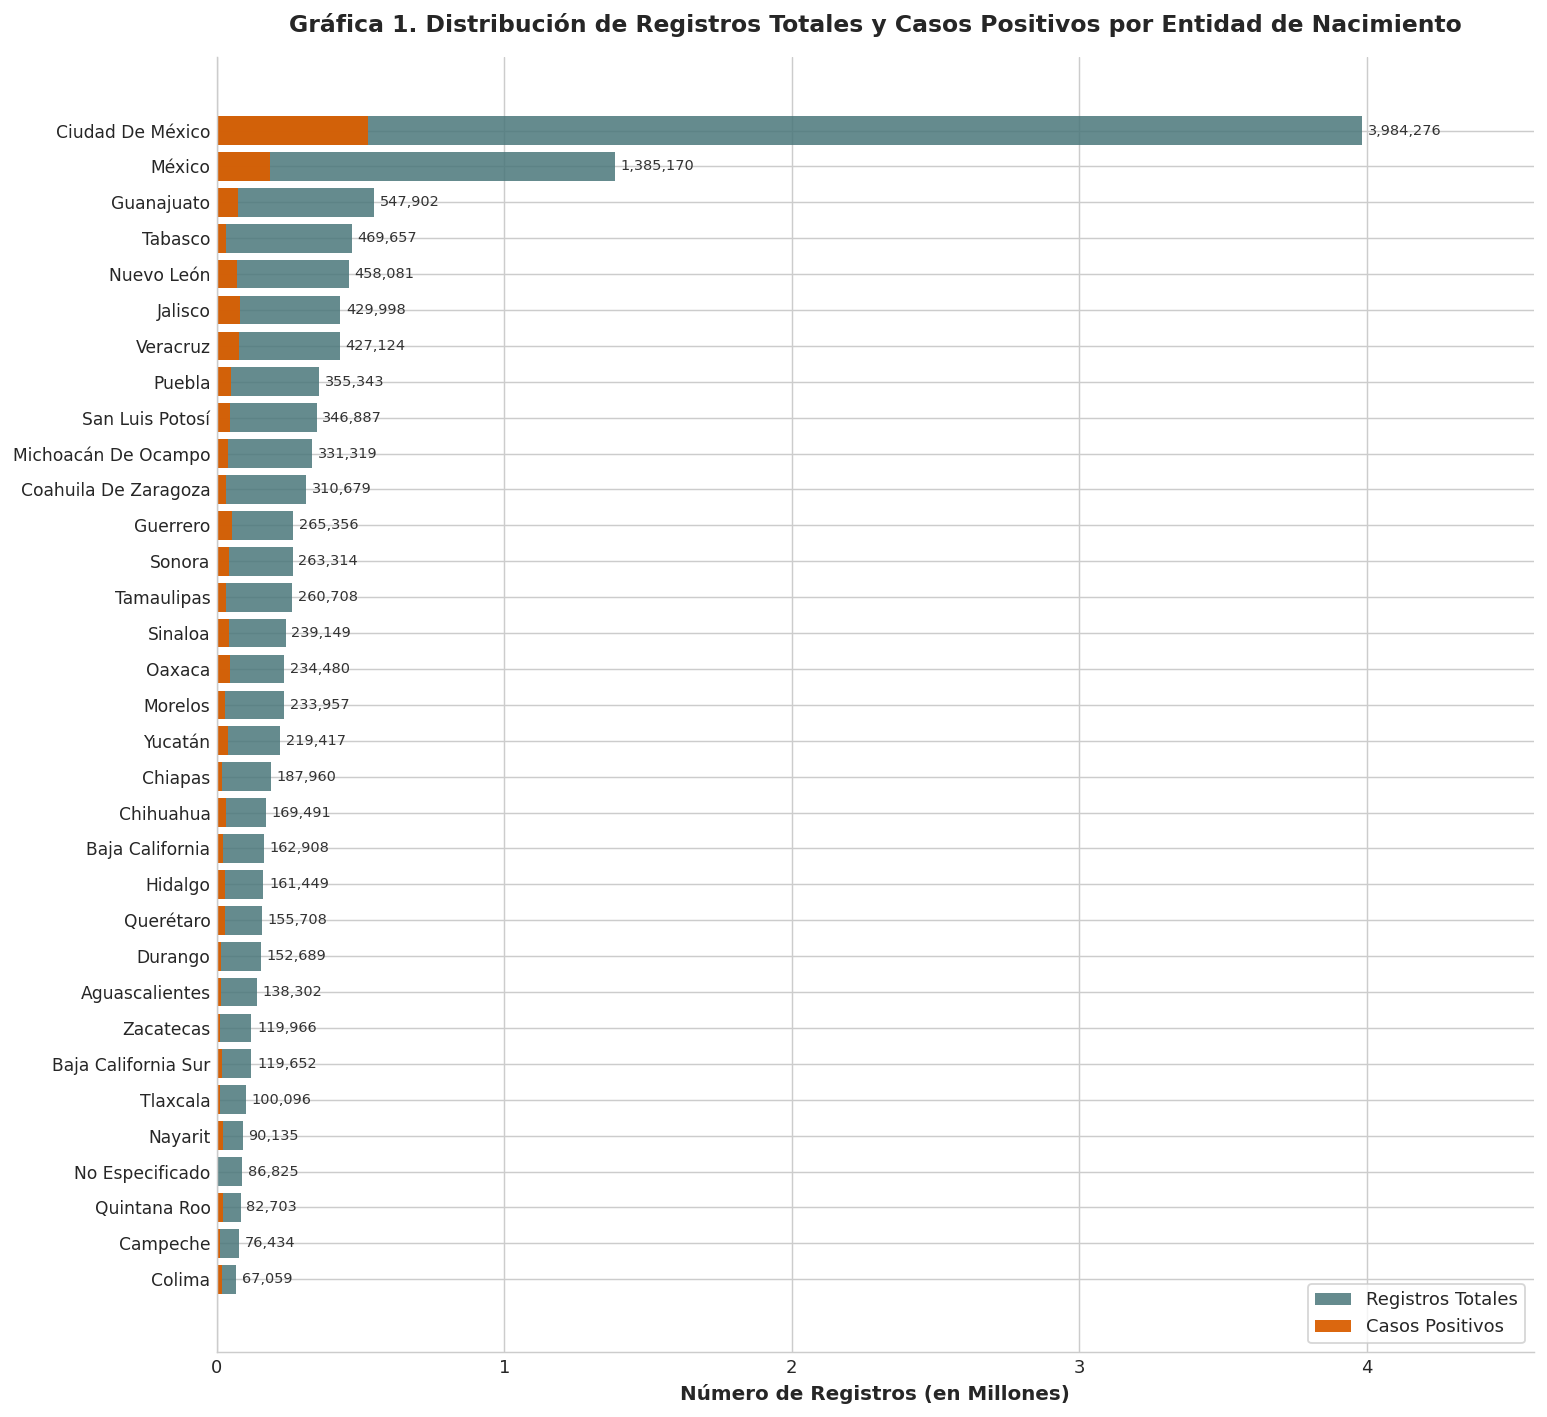

In [30]:
# Gráfica 1: Registros por entidad federativa

conteo_entidad = (
    df.groupby(
        ['ENTIDAD_NAC', 'RESULTADO_ANTIGENO'],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
)

conteo_entidad['Total'] = conteo_entidad.sum(axis=1)

# Renombrar código 99 (registros sin entidad de nacimiento especificada)
conteo_entidad = conteo_entidad.rename(
    index={'99': 'No Especificado'}
)

conteo_entidad = conteo_entidad.rename(
    index={99: 'No Especificado'}
)

conteo_entidad = conteo_entidad.sort_values(
    'Total',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 11))

y_pos = np.arange(len(conteo_entidad))

ax.barh(
    y_pos,
    conteo_entidad['Total'] / 1e6,
    color='#4A777A',
    alpha=0.85,
    label='Registros Totales'
)

if 'Positivo' in conteo_entidad.columns:
    ax.barh(
        y_pos,
        conteo_entidad['Positivo'] / 1e6,
        color='#D95F02',
        alpha=0.95,
        label='Casos Positivos'
    )

ax.set_yticks(y_pos)
ax.set_yticklabels(conteo_entidad.index, fontsize=9.5)

ax.set_xlabel(
    'Número de Registros (en Millones)',
    fontsize=11,
    fontweight='bold'
)

ax.set_title(
    'Gráfica 1. Distribución de Registros Totales y Casos Positivos por Entidad de Nacimiento',
    fontsize=13,
    fontweight='bold',
    pad=14
)

ax.legend(
    loc='lower right',
    frameon=True,
    fontsize=10
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for i, total in enumerate(conteo_entidad['Total']):
    ax.text(
        (total / 1e6) + 0.02,
        i,
        f"{total:,}",
        va='center',
        fontsize=8,
        color='#333333'
    )

plt.xlim(
    0,
    (conteo_entidad['Total'].max() / 1e6) * 1.15
)

plt.tight_layout()
plt.show()


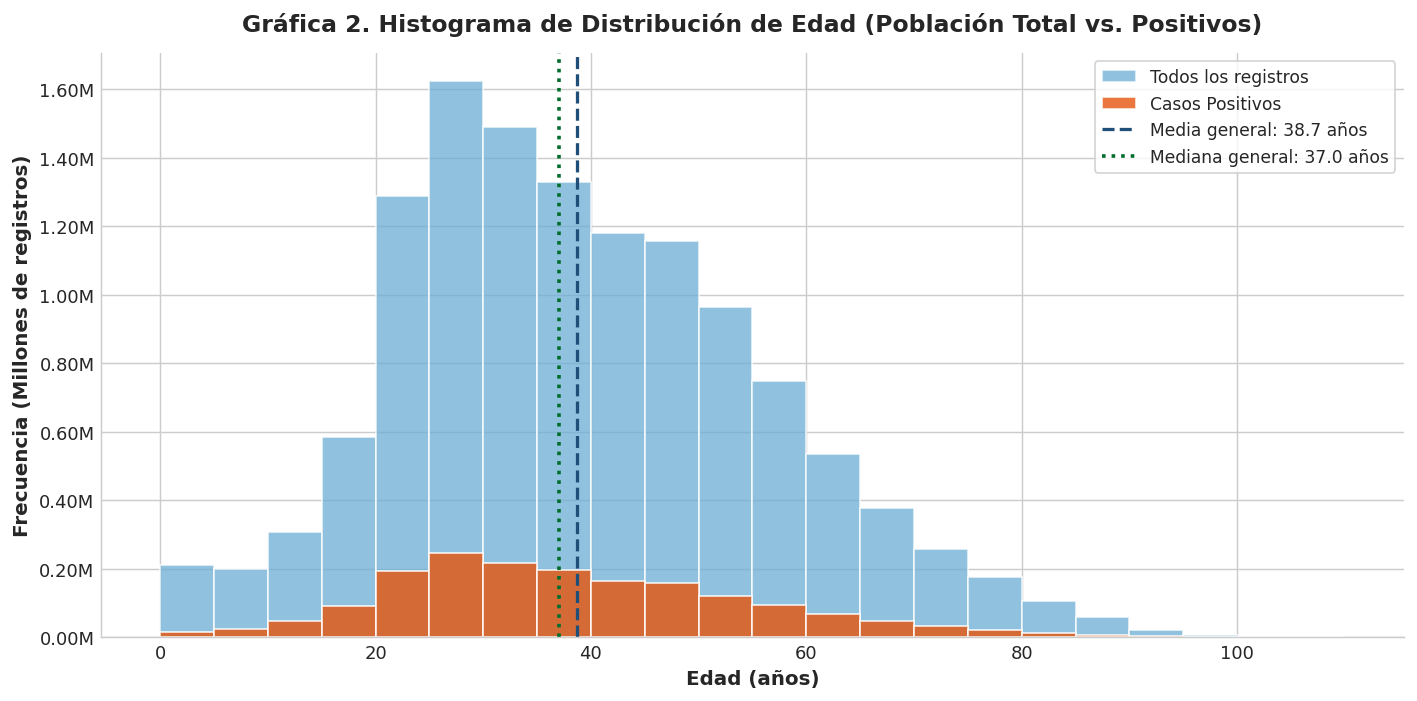

3565

In [31]:
# Gráfica 2: Histograma de edad
edades_totales = df['EDAD'][(df['EDAD'] >= 0) & (df['EDAD'] <= 110)].dropna()
edades_positivas = df.loc[df['RESULTADO_ANTIGENO'] == 'Positivo', 'EDAD']
edades_positivas = edades_positivas[(edades_positivas >= 0) & (edades_positivas <= 110)].dropna()

fig, ax = plt.subplots(figsize=(11, 5.5))
bins = np.arange(0, 112, 5)

ax.hist(edades_totales, bins=bins, color='#6BAED6', edgecolor='white', alpha=0.75, label='Todos los registros')
ax.hist(edades_positivas, bins=bins, color='#E6550D', edgecolor='white', alpha=0.80, label='Casos Positivos')

media_edad = edades_totales.mean()
mediana_edad = edades_totales.median()
ax.axvline(media_edad, color='#1F4E78', linestyle='--', linewidth=1.8, label=f'Media general: {media_edad:.1f} años')
ax.axvline(mediana_edad, color='#006D2C', linestyle=':', linewidth=2.0, label=f'Mediana general: {mediana_edad:.1f} años')

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.2f}M'))
ax.set_xlabel('Edad (años)', fontsize=11, fontweight='bold')
ax.set_ylabel('Frecuencia (Millones de registros)', fontsize=11, fontweight='bold')
ax.set_title('Gráfica 2. Histograma de Distribución de Edad (Población Total vs. Positivos)', fontsize=13, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=9.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

del edades_totales, edades_positivas
gc.collect()


**Interpretación:** La distribución de edades se concentra principalmente entre los 20 y 60 años, observándose una media de 38.7 años y una mediana de 37 años. Los casos positivos siguen una tendencia similar a la población total, aunque con una menor frecuencia absoluta.

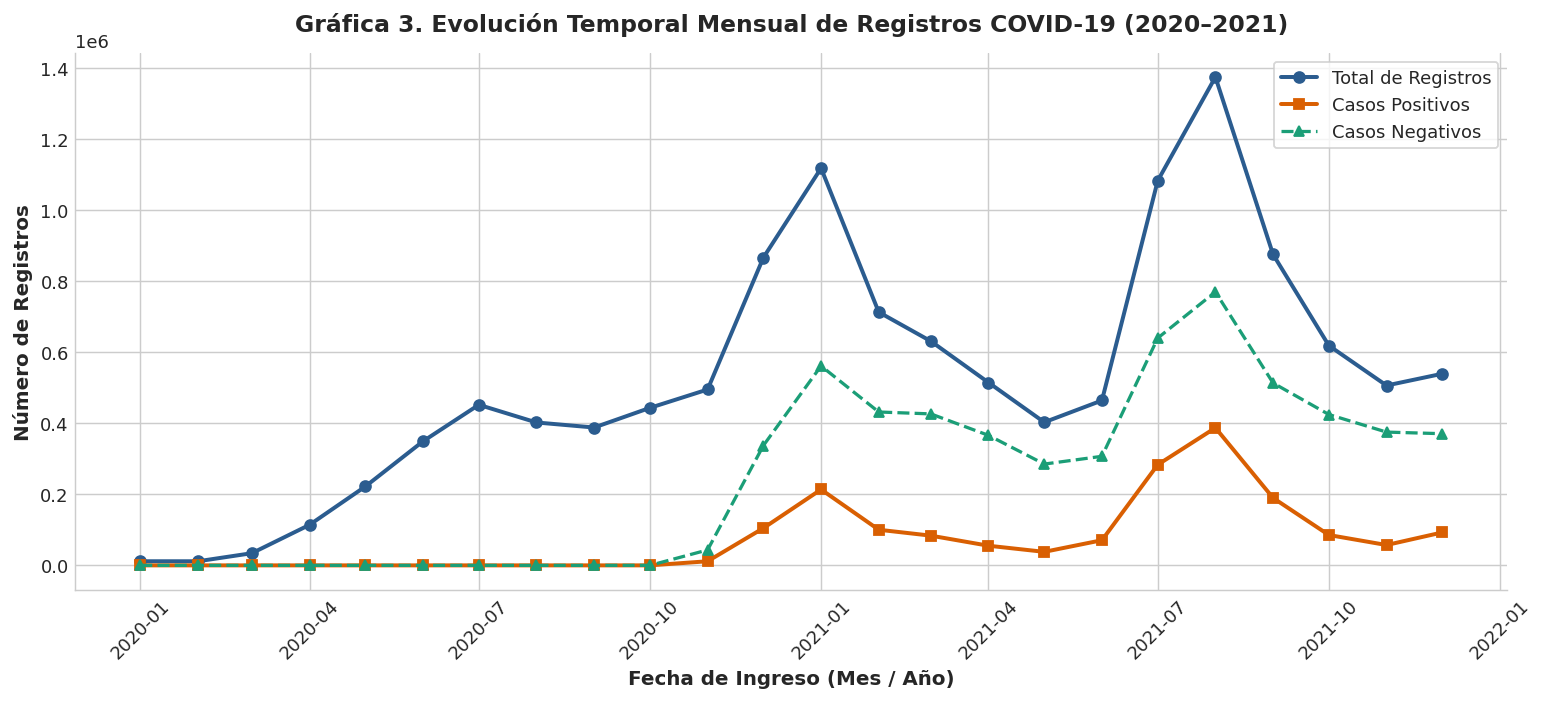

6149

In [32]:
# Gráfica 3: Evolución mensual por fecha de ingreso

df_tiempo = df[['FECHA_INGRESO', 'RESULTADO_ANTIGENO']].dropna(subset=['FECHA_INGRESO']).copy()

df_tiempo['MES_INGRESO'] = (
    df_tiempo['FECHA_INGRESO']
    .dt.to_period('M')
    .dt.to_timestamp()
)

serie_mensual = (
    df_tiempo
    .groupby(['MES_INGRESO', 'RESULTADO_ANTIGENO'], observed=False)
    .size()
    .unstack(fill_value=0)
)

serie_mensual['Total'] = serie_mensual.sum(axis=1)

serie_mensual = serie_mensual[
    (serie_mensual.index >= '2020-01-01') &
    (serie_mensual.index <= '2021-12-31')
]

fig, ax = plt.subplots(figsize=(12, 5.5))

ax.plot(
    serie_mensual.index,
    serie_mensual['Total'],
    marker='o',
    linewidth=2.2,
    color='#2B5C8F',
    label='Total de Registros'
)

if 'Positivo' in serie_mensual.columns:
    ax.plot(
        serie_mensual.index,
        serie_mensual['Positivo'],
        marker='s',
        linewidth=2.2,
        color='#D95F02',
        label='Casos Positivos'
    )

if 'Negativo' in serie_mensual.columns:
    ax.plot(
        serie_mensual.index,
        serie_mensual['Negativo'],
        marker='^',
        linewidth=1.8,
        linestyle='--',
        color='#1B9E77',
        label='Casos Negativos'
    )

ax.set_xlabel(
    'Fecha de Ingreso (Mes / Año)',
    fontsize=11,
    fontweight='bold'
)

ax.set_ylabel(
    'Número de Registros',
    fontsize=11,
    fontweight='bold'
)

ax.set_title(
    'Gráfica 3. Evolución Temporal Mensual de Registros COVID-19 (2020–2021)',
    fontsize=13,
    fontweight='bold',
    pad=12
)

ax.legend(frameon=True, fontsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

del df_tiempo
gc.collect()


**Interpretación:** La evolución mensual muestra un incremento progresivo de los registros durante 2020 y dos periodos de elevada actividad durante 2021. Los casos negativos representan la mayor proporción de registros durante la mayor parte del periodo analizado, mientras que los casos positivos presentan variaciones que coinciden con los principales picos epidémicos observados en México.

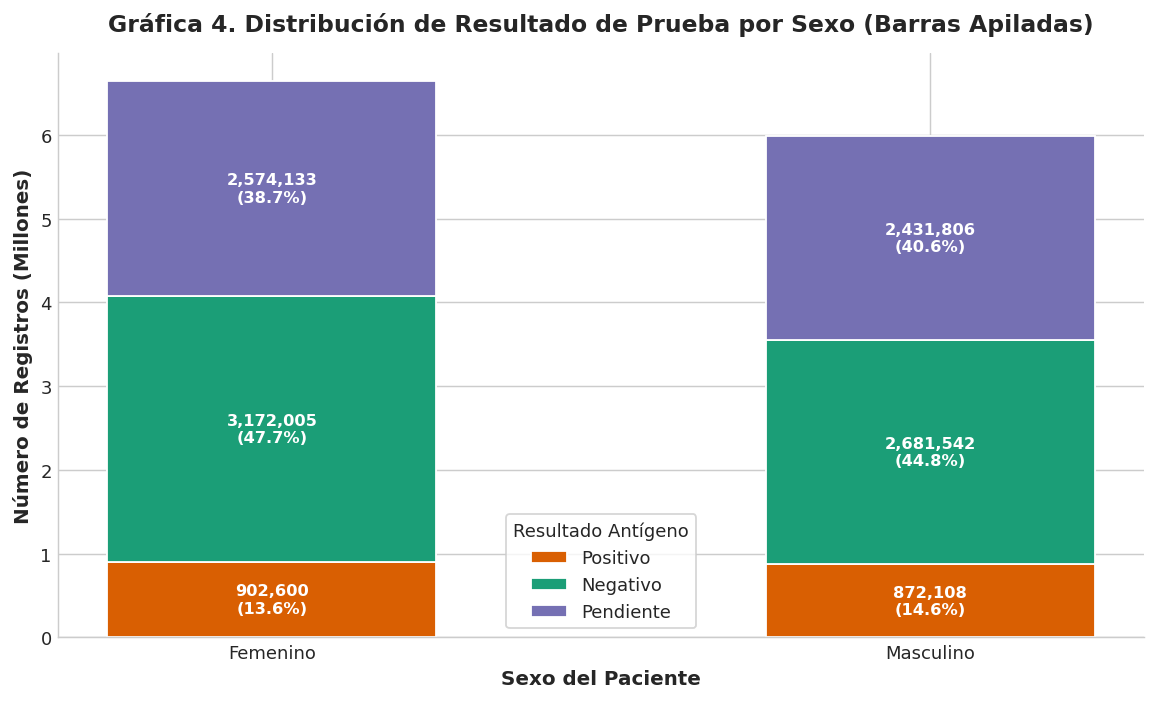

In [9]:
# Gráfica 4: Resultado de prueba por sexo
sexo_res = pd.crosstab(df['SEXO'], df['RESULTADO_ANTIGENO'])
sexo_res_pct = sexo_res.div(sexo_res.sum(axis=1), axis=0) * 100

colores_res = {'Positivo': '#D95F02', 'Negativo': '#1B9E77', 'Pendiente': '#7570B3'}
cols_ordenadas = [c for c in ['Positivo', 'Negativo', 'Pendiente'] if c in sexo_res.columns]

fig, ax = plt.subplots(figsize=(9, 5.5))
bottom = np.zeros(len(sexo_res))

for col in cols_ordenadas:
    vals = sexo_res[col].values / 1e6
    pcts = sexo_res_pct[col].values
    bars = ax.bar(sexo_res.index, vals, bottom=bottom, width=0.5, label=col, color=colores_res.get(col, '#888888'), edgecolor='white')
    for idx, bar in enumerate(bars):
        if vals[idx] > 0.25:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bottom[idx] + vals[idx] / 2,
                f"{sexo_res[col].iloc[idx]:,}\n({pcts[idx]:.1f}%)",
                ha='center', va='center', color='white', fontweight='bold', fontsize=9
            )
    bottom += vals

ax.set_xlabel('Sexo del Paciente', fontsize=11, fontweight='bold')
ax.set_ylabel('Número de Registros (Millones)', fontsize=11, fontweight='bold')
ax.set_title('Gráfica 4. Distribución de Resultado de Prueba por Sexo (Barras Apiladas)', fontsize=13, fontweight='bold', pad=12)
ax.legend(title='Resultado Antígeno', frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


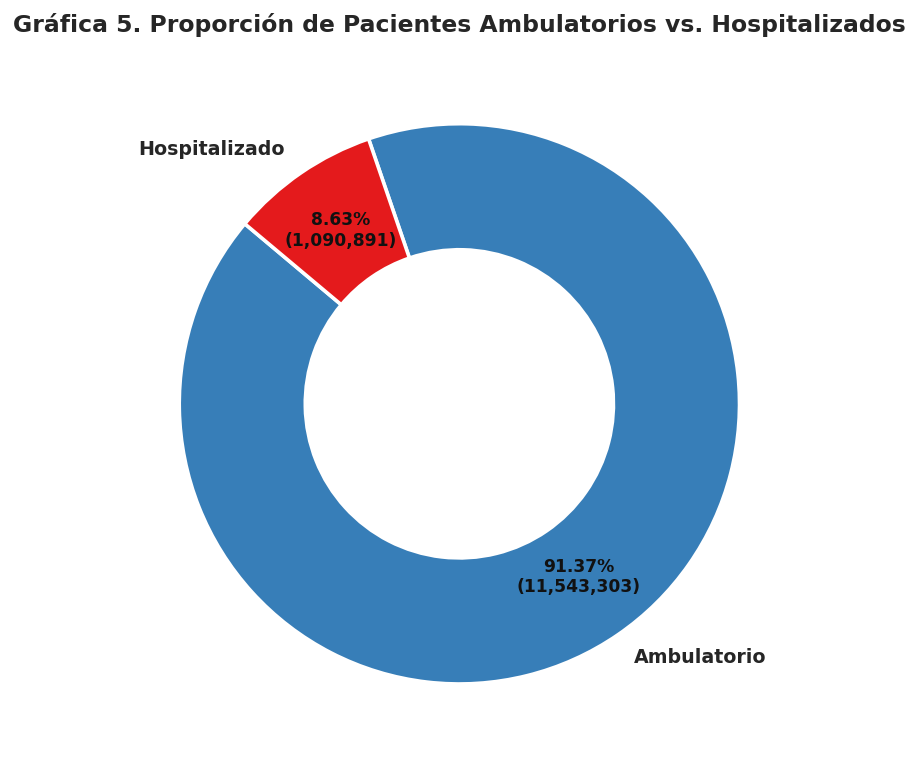

In [33]:

# Gráfica 5: Proporción por tipo de paciente
conteo_tipo = df['TIPO_PACIENTE'].value_counts()

fig, ax = plt.subplots(figsize=(7.5, 6))
colores_tipo = ['#377EB8', '#E41A1C']
wedges, texts, autotexts = ax.pie(
    conteo_tipo.values,
    labels=conteo_tipo.index,
    autopct=lambda pct: f"{pct:.2f}%\n({int(round(pct/100.*conteo_tipo.sum())):,})",
    startangle=140,
    colors=colores_tipo[:len(conteo_tipo)],
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10.5, fontweight='bold')
)

for autotext in autotexts:
    autotext.set_color('#111111')
    autotext.set_fontsize(9.5)

ax.set_title('Gráfica 5. Proporción de Pacientes Ambulatorios vs. Hospitalizados', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


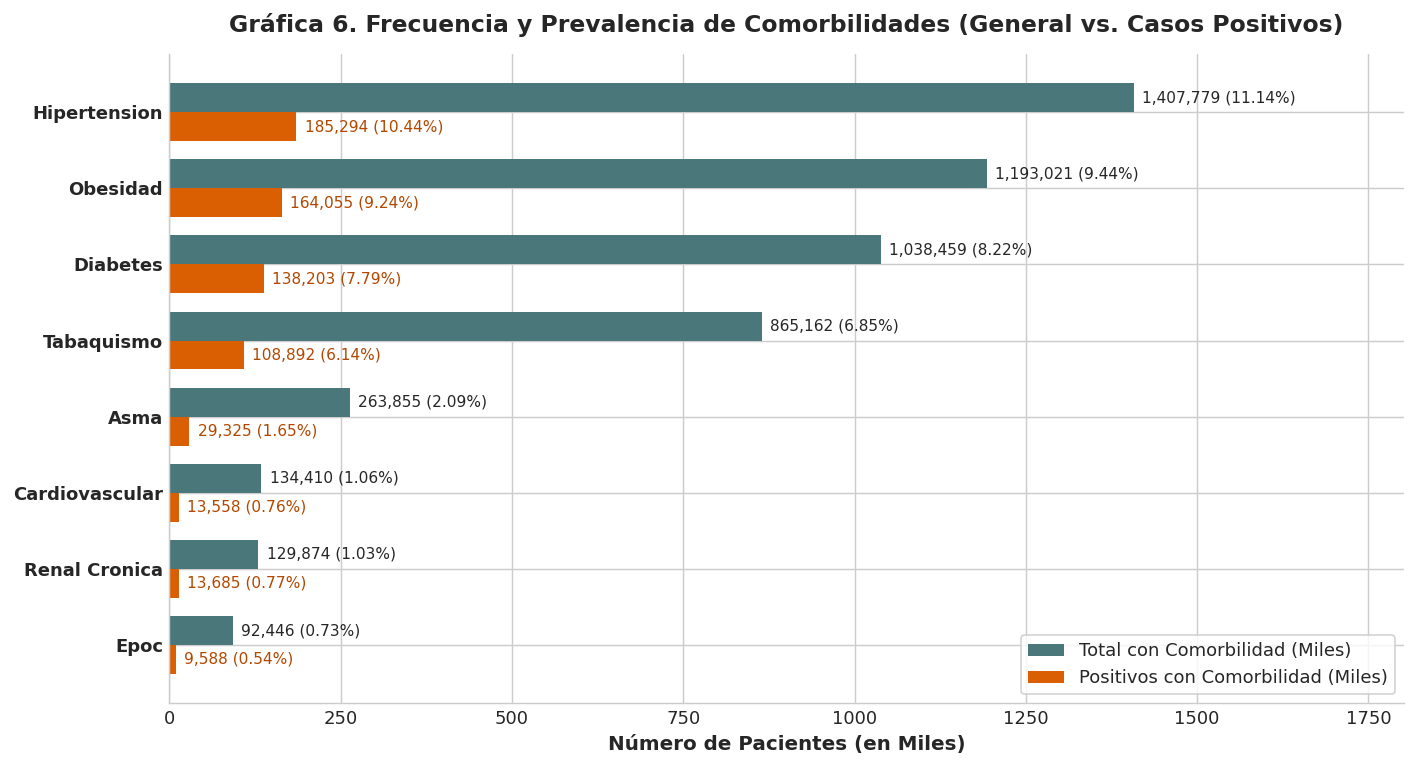

In [11]:
# Gráfica 6: Frecuencia de comorbilidades
comorbilidades_lista = [
    'DIABETES', 'HIPERTENSION', 'OBESIDAD', 'TABAQUISMO',
    'ASMA', 'CARDIOVASCULAR', 'EPOC', 'RENAL_CRONICA'
]

datos_comorb = []
es_positivo = (df['RESULTADO_ANTIGENO'] == 'Positivo')
total_pos = es_positivo.sum()

for col in comorbilidades_lista:
    tiene_comorb = (df[col] == 'Si')
    n_total_si = tiene_comorb.sum()
    n_pos_si = (tiene_comorb & es_positivo).sum()
    datos_comorb.append({
        'Comorbilidad': col.replace('_', ' ').title(),
        'Total_Si': n_total_si,
        'Positivos_Si': n_pos_si,
        'Pct_General': (n_total_si / total_registros) * 100,
        'Pct_En_Positivos': (n_pos_si / total_pos) * 100 if total_pos > 0 else 0
    })

df_comorb_plot = pd.DataFrame(datos_comorb).sort_values('Total_Si', ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))
y_idx = np.arange(len(df_comorb_plot))
altura = 0.38

ax.barh(y_idx + altura/2, df_comorb_plot['Total_Si'] / 1e3, height=altura, color='#4A777A', label='Total con Comorbilidad (Miles)')
ax.barh(y_idx - altura/2, df_comorb_plot['Positivos_Si'] / 1e3, height=altura, color='#D95F02', label='Positivos con Comorbilidad (Miles)')

for i, row in enumerate(df_comorb_plot.itertuples()):
    ax.text((row.Total_Si / 1e3) + 12, i + altura/2, f"{row.Total_Si:,} ({row.Pct_General:.2f}%)", va='center', fontsize=8.5)
    ax.text((row.Positivos_Si / 1e3) + 12, i - altura/2, f"{row.Positivos_Si:,} ({row.Pct_En_Positivos:.2f}%)", va='center', fontsize=8.5, color='#B34700')

ax.set_yticks(y_idx)
ax.set_yticklabels(df_comorb_plot['Comorbilidad'], fontsize=10, fontweight='bold')
ax.set_xlabel('Número de Pacientes (en Miles)', fontsize=11, fontweight='bold')
ax.set_title('Gráfica 6. Frecuencia y Prevalencia de Comorbilidades (General vs. Casos Positivos)', fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xlim(0, (df_comorb_plot['Total_Si'].max() / 1e3) * 1.28)

plt.tight_layout()
plt.show()


## 4. Probabilidad Simple y Condicional por Comorbilidad y Entidad

Se evalúan las 8 comorbilidades incluidas en el dataset (`DIABETES`, `HIPERTENSION`, `OBESIDAD`, `EPOC`, `ASMA`, `CARDIOVASCULAR`, `RENAL_CRONICA` y `TABAQUISMO`), tomando únicamente los registros con respuesta definida (`Si` / `No`) para cada condición $C_i$:

1. **Probabilidad Simple:**

$$
P(C_i)=\frac{n(C_i=\text{Si})}{n(C_i\in\{\text{Si},\text{No}\})}
$$

2. **Probabilidad Condicional de resultado positivo dado $C_i$:**

$$
P(\text{Positivo}\mid C_i)=
\frac{n(\text{Positivo}\cap C_i=\text{Si})}
{n(C_i=\text{Si})}
$$

3. **Probabilidad Condicional de padecer $C_i$ dado un resultado positivo:**

$$
P(C_i\mid \text{Positivo})=
\frac{n(\text{Positivo}\cap C_i=\text{Si})}
{n(\text{Positivo}\cap C_i\in\{\text{Si},\text{No}\})}
$$


In [34]:
# 1. PROBABILIDAD SIMPLE: P(Comorbilidad) en el total de la base de datos

total_general = len(df)
lista_prob_simple = []

for col in comorbilidades_lista:

    total_comorb = df[col].isin(['Sí', 'Si']).sum()

    prob_simple = total_comorb / total_general

    lista_prob_simple.append({
        'Comorbilidad': col,
        'Total Pacientes': f"{total_comorb:,}",
        'Probabilidad Simple': round(prob_simple, 5),
        'Porcentaje (%)': f"{prob_simple * 100:.2f}%"
    })

df_prob_simple = pd.DataFrame(lista_prob_simple)

print("=== TABLA 4A: PROBABILIDAD SIMPLE POR COMORBILIDAD ===")
display(df_prob_simple)


# 2. PROBABILIDAD CONDICIONAL: P(Comorbilidad | Entidad Federativa)
# Proporción de pacientes con cada comorbilidad dentro de cada estado

prob_condicional_estado = {}

for col in comorbilidades_lista:

    tiene_comorb = df[col].isin(['Sí', 'Si'])

    prob_condicional_estado[col] = (
        tiene_comorb
        .groupby(df['ENTIDAD_NAC'], observed=False)
        .mean() * 100
    ).round(2)

df_prob_condicional = pd.DataFrame(prob_condicional_estado)

# Renombrar el código 99 para facilitar la interpretación
df_prob_condicional = df_prob_condicional.rename(
    index={'99': 'No Especificado / Sin Entidad Registrada'}
)

df_prob_condicional = df_prob_condicional.rename(
    index={99: 'No Especificado / Sin Entidad Registrada'}
)

print("=== TABLA 4B-1: PROBABILIDAD CONDICIONAL P(Comorbilidad | Entidad Federativa) (%) ===")
display(df_prob_condicional)

=== TABLA 4A: PROBABILIDAD SIMPLE POR COMORBILIDAD ===


,Comorbilidad,Total Pacientes,Probabilidad Simple,Porcentaje (%)
0,DIABETES,"1,038,459",0.08219,8.22%
1,HIPERTENSION,"1,407,779",0.11143,11.14%
2,OBESIDAD,"1,193,021",0.09443,9.44%
3,TABAQUISMO,"865,162",0.06848,6.85%
4,ASMA,"263,855",0.02088,2.09%
5,CARDIOVASCULAR,"134,410",0.01064,1.06%
6,EPOC,"92,446",0.00732,0.73%
7,RENAL_CRONICA,"129,874",0.01028,1.03%


=== TABLA 4B-1: PROBABILIDAD CONDICIONAL P(Comorbilidad | Entidad Federativa) (%) ===


,DIABETES,HIPERTENSION,OBESIDAD,TABAQUISMO,ASMA,CARDIOVASCULAR,EPOC,RENAL_CRONICA
ENTIDAD_NAC,,,,,,,,
No Especificado / Sin Entidad Registrada,2.43,5.11,4.16,4.85,2.69,0.87,0.39,0.31
Aguascalientes,7.57,11.67,10.43,7.64,2.52,1.23,0.89,1.57
Baja California,8.50,14.26,14.10,7.06,3.68,1.52,0.80,0.97
Baja California Sur,7.18,11.07,12.57,5.51,2.89,1.05,0.33,0.72
Campeche,8.79,12.49,13.62,4.44,2.70,1.04,0.70,1.04
Chiapas,8.24,10.86,9.20,4.08,2.11,1.00,0.66,1.09
Chihuahua,10.56,16.45,12.10,8.60,3.20,1.87,1.20,1.39
Ciudad De México,6.51,8.69,7.64,9.14,1.87,0.83,0.47,0.59
Coahuila De Zaragoza,9.46,12.55,8.01,6.11,1.86,1.14,0.55,1.14


In [36]:
# Probabilidades desglosadas por entidad federativa

registros_estado = []

df['_IS_POS'] = (df['RESULTADO_ANTIGENO'] == 'Positivo').astype('int8')

for col in comorbilidades_lista:

    sub = df[df[col].isin(['Si', 'No'])][
        ['ENTIDAD_NAC', col, '_IS_POS']
    ].copy()

    sub['_IS_SI'] = (sub[col] == 'Si').astype('int8')
    sub['_SI_Y_POS'] = (sub['_IS_SI'] & sub['_IS_POS']).astype('int8')

    grp = sub.groupby(
        'ENTIDAD_NAC',
        observed=False
    ).agg(
        N_Validos=('_IS_SI', 'count'),
        N_Comorb=('_IS_SI', 'sum'),
        N_Pos_Comorb=('_SI_Y_POS', 'sum')
    ).reset_index()

    grp['Comorbilidad'] = col

    grp['P_Simple_Comorb'] = (
        grp['N_Comorb'] / grp['N_Validos']
    )

    grp['P_Cond_Pos_dado_Comorb'] = np.where(
        grp['N_Comorb'] > 0,
        grp['N_Pos_Comorb'] / grp['N_Comorb'],
        0.0
    )

    registros_estado.append(grp)

df.drop(columns=['_IS_POS'], inplace=True)

gc.collect()

df_prob_estados = pd.concat(
    registros_estado,
    ignore_index=True
)

matriz_p_simple = (
    df_prob_estados
    .pivot(
        index='ENTIDAD_NAC',
        columns='Comorbilidad',
        values='P_Simple_Comorb'
    ) * 100
)

matriz_p_simple = matriz_p_simple[comorbilidades_lista]

matriz_p_cond = (
    df_prob_estados
    .pivot(
        index='ENTIDAD_NAC',
        columns='Comorbilidad',
        values='P_Cond_Pos_dado_Comorb'
    ) * 100
)

matriz_p_cond = matriz_p_cond[comorbilidades_lista]

# Renombrar código 99 para facilitar la interpretación

matriz_p_simple = matriz_p_simple.rename(
    index={'99': 'No Especificado / Sin Entidad Registrada'}
)

matriz_p_simple = matriz_p_simple.rename(
    index={99: 'No Especificado / Sin Entidad Registrada'}
)

matriz_p_cond = matriz_p_cond.rename(
    index={'99': 'No Especificado / Sin Entidad Registrada'}
)

matriz_p_cond = matriz_p_cond.rename(
    index={99: 'No Especificado / Sin Entidad Registrada'}
)

print(
    "=== TABLA 4B-1: PROBABILIDAD CONDICIONAL "
    "P(Comorbilidad | Entidad Federativa) (%) ==="
)

display(
    matriz_p_simple.style
    .format('{:.2f}%')
    .background_gradient(cmap='YlGnBu', axis=None)
)

print(
    "\n=== TABLA 4B-2: PROBABILIDAD CONDICIONAL "
    "P(Positivo | Comorbilidad) POR ENTIDAD FEDERATIVA (%) ==="
)

display(
    matriz_p_cond.style
    .format('{:.2f}%')
    .background_gradient(cmap='OrRd', axis=None)
)

=== TABLA 4B-1: PROBABILIDAD CONDICIONAL P(Comorbilidad | Entidad Federativa) (%) ===


Comorbilidad,DIABETES,HIPERTENSION,OBESIDAD,TABAQUISMO,ASMA,CARDIOVASCULAR,EPOC,RENAL_CRONICA
ENTIDAD_NAC,,,,,,,,
No Especificado / Sin Entidad Registrada,2.44%,5.12%,4.17%,4.86%,2.69%,0.87%,0.39%,0.31%
Aguascalientes,7.57%,11.68%,10.44%,7.64%,2.52%,1.23%,0.89%,1.57%
Baja California,8.52%,14.29%,14.13%,7.08%,3.69%,1.52%,0.80%,0.97%
Baja California Sur,7.19%,11.08%,12.59%,5.51%,2.90%,1.05%,0.33%,0.72%
Campeche,8.80%,12.50%,13.63%,4.44%,2.70%,1.04%,0.70%,1.04%
Chiapas,8.24%,10.87%,9.21%,4.08%,2.12%,1.00%,0.66%,1.09%
Chihuahua,10.59%,16.48%,12.12%,8.62%,3.20%,1.88%,1.20%,1.39%
Ciudad De México,6.60%,8.81%,7.75%,9.26%,1.90%,0.84%,0.48%,0.60%
Coahuila De Zaragoza,9.51%,12.61%,8.05%,6.14%,1.87%,1.15%,0.55%,1.15%



=== TABLA 4B-2: PROBABILIDAD CONDICIONAL P(Positivo | Comorbilidad) POR ENTIDAD FEDERATIVA (%) ===


Comorbilidad,DIABETES,HIPERTENSION,OBESIDAD,TABAQUISMO,ASMA,CARDIOVASCULAR,EPOC,RENAL_CRONICA
ENTIDAD_NAC,,,,,,,,
No Especificado / Sin Entidad Registrada,8.99%,9.03%,10.01%,7.32%,8.44%,7.58%,8.61%,10.49%
Aguascalientes,11.37%,10.92%,11.24%,8.92%,7.34%,7.78%,8.69%,8.22%
Baja California,12.31%,12.62%,12.15%,12.65%,10.00%,10.91%,10.86%,9.66%
Baja California Sur,15.10%,14.93%,16.57%,15.68%,13.26%,13.18%,8.72%,12.79%
Campeche,14.22%,13.33%,13.03%,8.87%,12.07%,10.21%,9.19%,9.56%
Chiapas,7.41%,7.61%,8.79%,8.70%,5.69%,4.56%,5.98%,6.03%
Chihuahua,17.12%,17.58%,18.27%,17.19%,15.72%,14.55%,13.67%,13.10%
Ciudad De México,14.34%,13.70%,13.92%,12.28%,12.09%,11.31%,12.14%,11.79%
Coahuila De Zaragoza,9.77%,9.92%,10.10%,10.13%,7.96%,7.10%,5.95%,8.13%


**Nota:** La categoría "No Especificado / Sin Entidad Registrada" corresponde a registros cuyo valor original de entidad federativa aparece codificado como 99 en la base de datos. Estos registros se conservan para mantener la totalidad de los datos analizados.


## 5. Ejercicio de Distribución Normal

### Planteamiento
Considerando que el número de casos diarios sigue una distribución normal con media $\mu = 2360$ y desviación estándar $\sigma = 714$:
$$X \sim N(\mu = 2360, \sigma = 714)$$

Se calcula la probabilidad de observar entre $2000$ y $3000$ casos:
$$P(2000 \le X \le 3000)$$

### Desarrollo mediante Estandarización ($Z$)
Se aplica $Z = \frac{X - \mu}{\sigma}$ en ambos límites:

1. **Límite inferior ($x_1 = 2000$):**
   $$z_1 = \frac{2000 - 2360}{714} = \frac{-360}{714} \approx -0.5042$$

2. **Límite superior ($x_2 = 3000$):**
   $$z_2 = \frac{3000 - 2360}{714} = \frac{640}{714} \approx 0.8964$$

3. **Cálculo con la función de distribución acumulada $\Phi(z)$:**
   $$P(2000 \le X \le 3000) = P(-0.5042 \le Z \le 0.8964) = \Phi(0.8964) - \Phi(-0.5042)$$
   $$P(2000 \le X \le 3000) \approx 0.81498 - 0.30706 = 0.50792 \quad (50.79\%)$$

Valor Z para X = 2000: -0.5042
Valor Z para X = 3000: 0.8964
Probabilidad P(2000 <= X <= 3000): 0.5079 (50.79%)


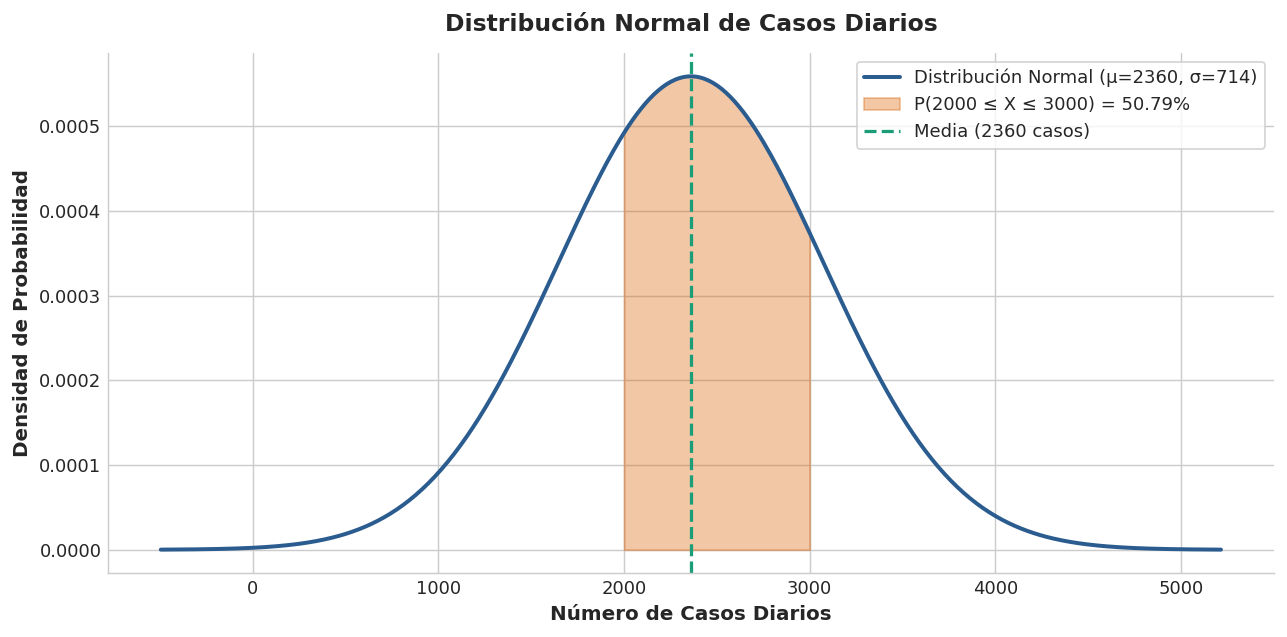

In [26]:
# Parámetros dados en el problema
media = 2360
desv_est = 714
x1 = 2000
x2 = 3000

# Estandarización a valores Z
z1 = (x1 - media) / desv_est
z2 = (x2 - media) / desv_est

# Cálculo de P(2000 <= X <= 3000) usando la función de distribución acumulada (CDF)
prob_intervalo = norm.cdf(x2, loc=media, scale=desv_est) - norm.cdf(x1, loc=media, scale=desv_est)

print(f"Valor Z para X = 2000: {z1:.4f}")
print(f"Valor Z para X = 3000: {z2:.4f}")
print(f"Probabilidad P(2000 <= X <= 3000): {prob_intervalo:.4f} ({prob_intervalo * 100:.2f}%)")

# Gráfica de la campana de Gauss sombreando el área entre 2000 y 3000 casos
x = np.linspace(media - 4*desv_est, media + 4*desv_est, 500)
y = norm.pdf(x, loc=media, scale=desv_est)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, y, color='#2B5C8F', linewidth=2.2, label='Distribución Normal (μ=2360, σ=714)')

x_sombra = np.linspace(x1, x2, 300)
ax.fill_between(x_sombra, norm.pdf(x_sombra, loc=media, scale=desv_est), color='#D95F02', alpha=0.35,
                label=f'P(2000 ≤ X ≤ 3000) = {prob_intervalo*100:.2f}%')
ax.axvline(media, color='#1B9E77', linestyle='--', linewidth=1.8, label='Media (2360 casos)')

ax.set_xlabel(
    'Número de Casos Diarios',
    fontsize=11,
    fontweight='bold'
)
ax.set_ylabel('Densidad de Probabilidad', fontsize=11, fontweight='bold')
ax.set_title(
    'Distribución Normal de Casos Diarios',
    fontsize=13,
    fontweight='bold',
    pad=12
)
ax.legend(frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [28]:
pos_total = (df['RESULTADO_ANTIGENO'] == 'Positivo').sum()
neg_total = (df['RESULTADO_ANTIGENO'] == 'Negativo').sum()
pend_total = (df['RESULTADO_ANTIGENO'] == 'Pendiente').sum()

hosp_total = (df['TIPO_PACIENTE'] == 'Hospitalizado').sum()
amb_total = (df['TIPO_PACIENTE'] == 'Ambulatorio').sum()

top_comorb = df_prob_simple.sort_values(
    'Probabilidad Simple',
    ascending=False
).iloc[0]

print("=== RESUMEN DE RESULTADOS ===")

print(f"1. Total de registros analizados: {total_registros:,}")

print(
    f"2. Resultado antígeno: "
    f"{pos_total:,} Positivos ({pos_total/total_registros*100:.2f}%), "
    f"{neg_total:,} Negativos ({neg_total/total_registros*100:.2f}%), "
    f"{pend_total:,} Pendientes ({pend_total/total_registros*100:.2f}%)."
)

print(
    f"3. Tipo de paciente: "
    f"{amb_total:,} Ambulatorios ({amb_total/total_registros*100:.2f}%) vs. "
    f"{hosp_total:,} Hospitalizados ({hosp_total/total_registros*100:.2f}%)."
)

print(
    f"4. Comorbilidad más frecuente: "
    f"{top_comorb['Comorbilidad']} "
    f"con P(C) = {top_comorb['Probabilidad Simple']*100:.2f}%."
)

=== RESUMEN DE RESULTADOS ===
1. Total de registros analizados: 12,634,194
2. Resultado antígeno: 1,774,708 Positivos (14.05%), 5,853,547 Negativos (46.33%), 5,005,939 Pendientes (39.62%).
3. Tipo de paciente: 11,543,303 Ambulatorios (91.37%) vs. 1,090,891 Hospitalizados (8.63%).
4. Comorbilidad más frecuente: HIPERTENSION con P(C) = 11.14%.


## 6. Conclusiones Grupales

1. **Distribución demográfica y temporal:** La mayor concentración de registros se encuentra en adultos en edad productiva (mediana de 37 años) y la mayoría de los casos registrados recibieron atención ambulatoria frente a una proporción menor de hospitalizaciones. La serie mensual refleja claramente los picos de contagio ocurridos entre 2020 y 2021.
2. **Comorbilidades y probabilidad:** Las enfermedades crónicas con mayor probabilidad simple $P(C_i)$ en la base de datos son hipertensión, obesidad y diabetes. Al calcular la probabilidad condicional $P(\text{Positivo} \mid C_i)$ por entidad federativa, se observan diferencias importantes entre estados debido tanto a la incidencia local como al volumen de pruebas aplicadas en cada región.
3. **Distribución Normal:** Para una variable $X \sim N(2360, 714)$, la probabilidad de registrar entre $2000$ y $3000$ casos es de **$50.79\%$** ($P(-0.5042 \le Z \le 0.8964) = 0.5079$), concentrando poco más de la mitad de la probabilidad alrededor de la media.
4. **Manejo del dataset:** El uso de tipos de datos categóricos (`category`) permitió trabajar con los 12.63 millones de registros completos dentro del entorno de Colab sin necesidad de muestrear o recortar el archivo.

## 7. Conclusiones Personales

* **Aaron Antonio Contreras Herrera:** Durante el semestre en Probabilidad y Estadística entendí mucho mejor para qué sirven realmente las medidas descriptivas, las tablas de frecuencia y los distintos tipos de gráficas cuando se aplican a un problema real y no solo a ejercicios pequeños de libreta. Al trabajar con esta base de datos de COVID-19 en Python me di cuenta de lo importante que es revisar bien la información antes de graficar, porque cualquier detalle en los formatos puede cambiar los resultados. Usar Google Colab con librerías como pandas y matplotlib fue una muy buena experiencia, ya que facilita analizar millones de datos en segundos y presentar los resultados de una forma clara y visual.

* **Yael Arturo Aparicio Guzman:** En esta materia aprendí a interpretar datos desde un enfoque más analítico, sobre todo al calcular probabilidades simples y condicionales o al trabajar con la distribución normal, temas que al principio pueden parecer algo teóricos en clase. Al aplicarlos en el proyecto noté cómo cambian las probabilidades según el estado o las comorbilidades de los pacientes, lo que ayuda bastante a entender el comportamiento real de los contagios. Programar el análisis en Python me pareció muy práctico para automatizar los cálculos y comprobar que los resultados obtenidos con código coinciden con las fórmulas vistas en clase.

* **Yahir Fernando Vargas Calderón:** Llevar a cabo este proyecto me sirvió bastante para conectar lo que vimos en Probabilidad y Estadística con lo que hacemos en Sistemas Computacionales. En la materia aprendimos a obtener medidas de tendencia central, probabilidades y modelos de distribución, pero pasar eso a Python con un archivo tan pesado de más de doce millones de registros fue un reto distinto, ya que tuvimos que filtrar columnas y cuidar la memoria para que Colab no se trabara. Al final, trabajar con pandas y generar nuestras propias gráficas me dejó una buena experiencia sobre cómo aprovechar la programación para analizar grandes cantidades de información sin tener que hacerlo todo manual.